In [121]:
%matplotlib widget
import importlib
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import pandas as pd
import io
import matplotlib
from scipy.optimize import fsolve
import scipy as sc
from mpmath import findroot
import mpmath


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\COMSOL\Acoustic\Sphere in homogeneous medium')
import Analytical_model_func as Analytical_model_func
importlib.reload(Analytical_model_func)
from Analytical_model_func import *


import matplotlib as mpl
mpl.rcParams["font.size"] = 15

#Material properties : sphere is medium 1, environment is medium 2

In [122]:

R_sphere = 100e-9
Material_dic = {}

Material_dic['Au'] = Material("Au", E = 78e9, nu = 0.44, rho = 19300)
Material_dic['Au'].R = R_sphere

Material_dic['Si'] = Material("Si", E = 73.1e9, nu = 0.17, rho = 2203)
Material_dic['H2O'] = Material("H2O", E = 2.2e9, nu = 0.49, rho = 1000) # The E value is not viable

#Material_dic['Si'] = Material("Si", E = 73.1e9, nu = 0.44, rho = 22003)



def print_impedance_ratio_and_delta(mat1, mat2) :
    print("Z2/Z1 = {:.2f} / Delta = {:.2f}".format(mat2.Z/mat1.Z, mat2.rho/mat1.rho ))

print_impedance_ratio_and_delta(Material_dic['Au'], Material_dic['Si'])

print_impedance_ratio_and_delta(Material_dic['Au'], Material_dic['H2O'])

Z2/Z1 = 0.19 / Delta = 0.11
Z2/Z1 = 0.09 / Delta = 0.05


In [ ]:
print(Material_dic['Si'].cL)

5972.079596965294


In [124]:
Solver_param = {}
Solver_param['x_low'], Solver_param['x_high'], Solver_param['n_x'] = 0.1, 10, 100
Solver_param['y_low'], Solver_param['y_high'], Solver_param['n_y'] = 0, 1, 3

res = Solve_eigenvalues(Material_dic['Au'], Material_dic['Si'], R_sphere=R_sphere, **Solver_param)

In [ ]:
def print_results(res) :
    for i in range(len(res['freq'])) :
        print("mode {} : f = {:.2f} GHz / Q = {:.2f}, gamma_reduced = {:.3f}".format(i, res['freq'][i]*1e-9, res['Q'][i], res['gamma_reduced'][i]))
print_results(res)

mode 0 : f = 17.78 GHz / Q = 10.04, gamma_reduced = 0.154
mode 1 : f = 36.00 GHz / Q = 17.31, gamma_reduced = 0.181
mode 2 : f = 54.16 GHz / Q = 25.26, gamma_reduced = 0.186


In [1]:
fig, ax = plt.subplots()
#ax.scatter(freq*1e-9, Q)
#ax.scatter(res['omega_reduced']*1e-9, res['Q'])
ax.scatter(res['freq']*1e-9, res['Q'])

ax.set_xlabel('Freq (GHz)')
ax.set_ylabel('Q')

plt.tight_layout()

NameError: name 'plt' is not defined

In [127]:
dir_root = r'H:\commun\Utilisateur FNO\Nathan\COMSOL\Acoustic - sphere in homogeneous medium\Convergence test'

fname_3 = r'Au_sphere_in_Si - Change_scaling_curvature and r_PML - simu 3'
Res_simu_3 = open_COMSOL_results(dir_root, fname_3, ['t_PML', 'scaling_factor_curvature'])


fname_4 = r'Au_sphere_in_Si - mesh_size - simu 4'
Res_simu_4 = open_COMSOL_results(dir_root, fname_4, ['mesh_max'])

fname_5 = r'Au_sphere_in_Si - r_PML - simu 5'
Res_simu_5 = open_COMSOL_results(dir_root, fname_5, ['mesh_max'])

FileNotFoundError: [Errno 2] No such file or directory: 'Au_sphere_in_Si - Change_scaling_curvature and r_PML - simu 3.csv'

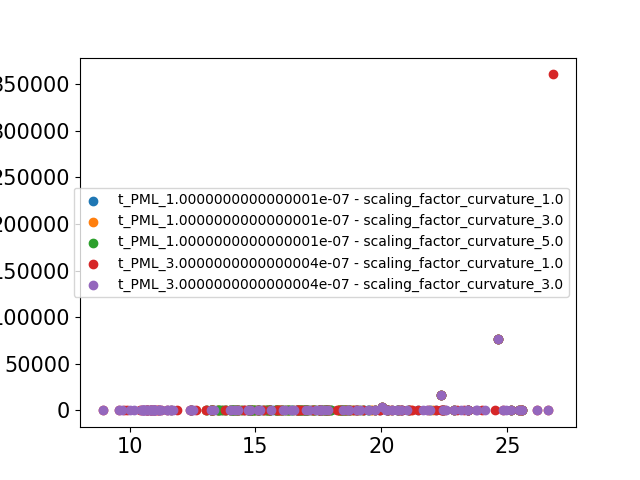

In [ ]:
fig, ax = plt.subplots()
for key in Res_simu_3 :
    ax.scatter(Res_simu_3[key]['freq']*1e-9, Res_simu_3[key]['Q'], label = key)
    
ax.legend(fontsize=10)

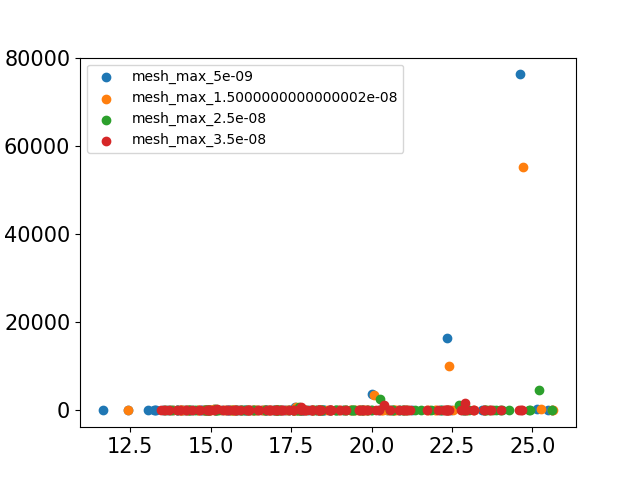

In [ ]:
fig, ax = plt.subplots()
for key in Res_simu_4 :
    ax.scatter(Res_simu_4[key]['freq']*1e-9, Res_simu_4[key]['Q'], label = key)
    
ax.legend(fontsize=10)

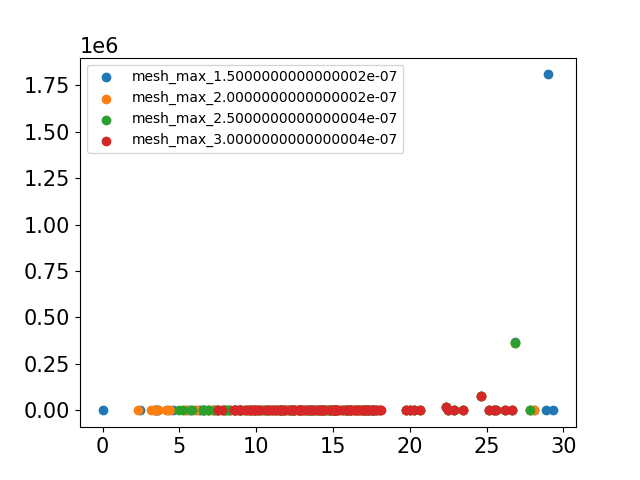

In [ ]:
fig, ax = plt.subplots()
for key in Res_simu_5 :
    ax.scatter(Res_simu_5[key]['freq']*1e-9, Res_simu_5[key]['Q'], label = key)
    
ax.legend(fontsize=10)